# DemandLab: exploration and results
Daily bike rentals, UCI Bike Sharing (2011-2012). Run `python -m demandlab.train` first; this notebook only explores and reads saved results.

In [1]:
import json, matplotlib.pyplot as plt, pandas as pd
from demandlab.data import load_raw, get_series
from demandlab.analysis import trend, weekday_profile, month_profile, detect_anomalies
raw = load_raw(); y = get_series(raw, 'total'); y.describe().round(0)

count     731.0
mean     4504.0
std      1937.0
min        22.0
25%      3152.0
50%      4548.0
75%      5956.0
max      8714.0
Name: total, dtype: float64

## Trend

{'slope_per_day': 5.76881832841138, 'intercept': 2398.7301473391494, 'first_365_mean': 3405.7616438356163, 'last_365_mean': 5608.991780821918, 'growth': 0.646912604989289}


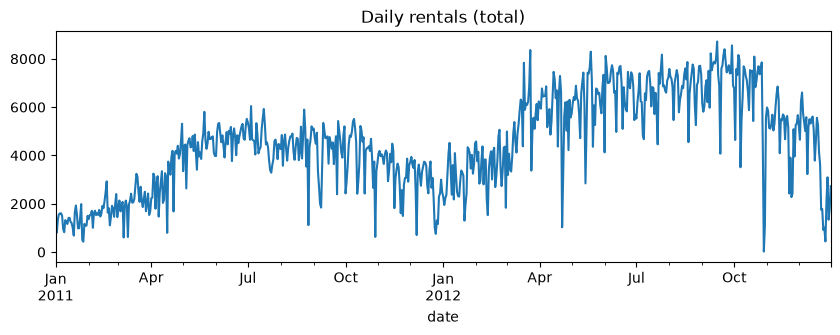

In [2]:
print(trend(y))
y.plot(figsize=(10,3), title='Daily rentals (total)'); plt.show()

## Seasonality (index vs overall mean; 1.0 = average)

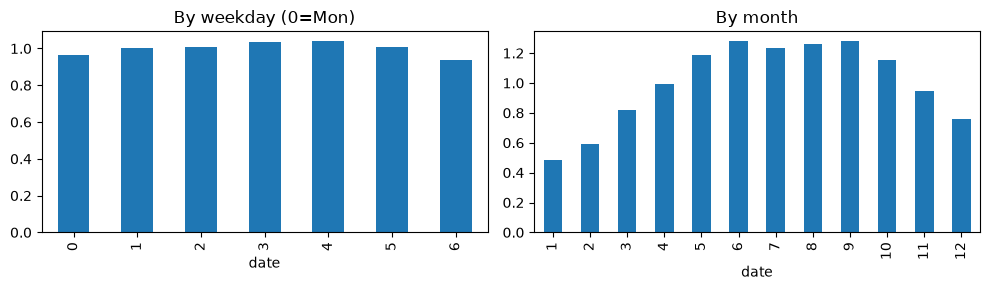

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10,3))
weekday_profile(y).plot.bar(ax=ax[0], title='By weekday (0=Mon)')
month_profile(y).plot.bar(ax=ax[1], title='By month'); plt.tight_layout(); plt.show()

## Anomalies (robust z-score vs rolling median)

In [4]:
a = detect_anomalies(y); print(len(a), 'flagged days'); a.round(1)

27 flagged days


,value,expected,robust_z
date,,,
2011-02-18,2927.0,1710.0,4.2
2011-03-06,605.0,1956.5,-4.0
2011-03-10,623.0,2066.5,-4.7
2011-03-18,3239.0,2077.0,3.6
2011-04-16,795.0,3226.5,-4.8
2011-04-22,1683.0,3586.5,-3.7
2011-08-27,1115.0,4411.0,-5.8
2011-09-07,1996.0,4586.5,-4.2
2011-09-08,1842.0,4525.0,-4.1


## Model comparison (test = last 90 days, never used for choosing the model)

In [5]:
m = pd.read_csv('reports/metrics.csv'); m[(m.split=='test')].pivot(index='model', columns='series', values='WAPE').round(3)

series,casual,registered,total
model,,,
gradient_boosting,0.471,0.244,0.325
random_forest,0.516,0.268,0.371
ridge_a1,0.430,0.230,0.248
ridge_a10,0.430,0.231,0.247
seasonal_naive,0.501,0.276,0.282


In [6]:
r = json.load(open('reports/results.json'))['series']
for s, v in r.items(): print(s, 'chosen:', v['chosen_model'], '| test:', {k: round(x,3) for k,x in v['test']['chosen'].items()}, '| baseline WAPE:', round(v['test']['baseline']['WAPE'],3))

total chosen: ridge_a10 | test: {'MAE': 1272.081, 'RMSE': 1834.344, 'WAPE': 0.247} | baseline WAPE: 0.281
casual chosen: ridge_a1 | test: {'MAE': 323.765, 'RMSE': 443.163, 'WAPE': 0.43} | baseline WAPE: 0.501
registered chosen: ridge_a10 | test: {'MAE': 1015.99, 'RMSE': 1551.434, 'WAPE': 0.231} | baseline WAPE: 0.277


## Failure cases (largest test errors, series `total`)

In [7]:
pd.DataFrame(r['total']['worst_test_days']).round(0)

,date,actual,predicted,abs_error
0,2012-10-29,22.0,6374.0,6352.0
1,2012-10-30,1096.0,6626.0,5530.0
2,2012-12-26,441.0,5408.0,4967.0
3,2012-12-24,920.0,5307.0,4387.0
4,2012-12-25,1013.0,5184.0,4171.0
